<a href="https://colab.research.google.com/github/vennela2604/Soil-Health/blob/main/Soil_Health_parameters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Analysis of Soil Health Parameters Across Different States and Their Correlation with Crop Productivity

* **Course-End Project:** Soil Health & Crop Analytics
project NO.62
* **Department:** Department of Information Technology, Chaitanya Bharathi Institute of Technology (CBIT), Hyderabad.

## Problem Overview
This notebook investigates soil health parameters (such as pH, Organic Carbon, Nitrogen, Phosphorus, and Potassium) across different regions, cleans missing readings, groups data, and visualizes nutrient distributions to evaluate agricultural productivity trends.

## Environment & Technologies
* **Python Version:** Python 3.x
* **Libraries Used:** Pandas, NumPy, Matplotlib, Seaborn


* **Technologies Used:** Python 3, Pandas, NumPy, Matplotlib, Seaborn  
* **Dataset:** Government of India Agricultural Datasets (Soil Health Card Scheme)  

---

### Project Overview
This notebook investigates the relationship between key soil health characteristics (such as pH, Organic Carbon, Nitrogen, Phosphorus, and Potassium) and agricultural crop productivity across various Indian states.

### Key Objectives:
1. **Data Inspection & Cleaning:** Verify data integrity, check for missing values, and handle schema variations robustly.
2. **Exploratory Data Analysis (EDA):** Compute descriptive statistics and compare soil nutrient distributions across different geographic regions.
3. **Correlation Analysis:** Generate correlation heatmaps and scatter plots to analyze linear relationships between soil parameters and crop yields.
4. **Conclusion & Limitations:** Summarize actionable insights while acknowledging agricultural and data limitations (such as the impact of climate and irrigation).

In [ ]:
# Import essential Python libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure seaborn style for clean academic plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os
from google.colab import files

# Define file path (adjust if running locally vs Google Colab)
file_path = 'soil_health_crop_productivity_2000_2011_180rows.xlsx'

if not os.path.exists(file_path):
    print("File not found in local directory. Please upload your dataset file (.xlsx or .csv):")
    uploaded = files.upload()
    file_path = list(uploaded.keys())[0]

# Load the Excel dataset safely
try:
    # Check sheet names first
    xls = pd.ExcelFile(file_path)
    print(f"Available sheets in Excel file: {xls.sheet_names}")

    # Read the first sheet
    df = pd.read_excel(file_path, sheet_name=0)
    print(f"\nDataset successfully loaded from: {file_path}")
except Exception as e:
    print(f"Error loading file: {e}")

File not found in local directory. Please upload your dataset file (.xlsx or .csv):


Saving Soil_Health_and_Crop_Productivity_2011_2019.xlsx to Soil_Health_and_Crop_Productivity_2011_2019.xlsx
Available sheets in Excel file: ['Dataset_2011_2019', 'Summary_Dashboard']

Dataset successfully loaded from: Soil_Health_and_Crop_Productivity_2011_2019.xlsx


In [ ]:
# Display the total number of rows and columns
print(f"Dataset Shape (Rows, Columns): {df.shape}")

# Display the first 5 rows of the dataset
print("\nFirst 5 rows of the dataset:")
display(df.head())

# Display data types and non-null counts for each column
print("\nDataset Information & Data Types:")
df.info()

Dataset Shape (Rows, Columns): (900, 12)

First 5 rows of the dataset:


,Sample_ID,Year,State,District,Crop,pH,Organic_Carbon_%,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,EC_dS_m,Productivity_Qtl_Ha
0,SHC-1001,2011,Punjab,Ludhiana,Rice,7.30,0.40,171.5,14.1,446.5,1.12,25.90
1,SHC-1002,2011,Punjab,Ludhiana,Wheat,5.56,1.46,394.7,24.9,172.7,0.41,27.54
2,SHC-1003,2011,Punjab,Amritsar,Wheat,7.34,0.38,216.4,35.6,282.4,1.43,21.43
3,SHC-1004,2011,Punjab,Amritsar,Maize,7.04,0.97,135.3,52.5,168.2,0.21,24.98
4,SHC-1005,2011,Punjab,Jalandhar,Maize,5.79,1.09,265.3,18.5,298.1,0.16,23.24



Dataset Information & Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Sample_ID            900 non-null    object 
 1   Year                 900 non-null    int64  
 2   State                900 non-null    object 
 3   District             900 non-null    object 
 4   Crop                 900 non-null    object 
 5   pH                   900 non-null    float64
 6   Organic_Carbon_%     900 non-null    float64
 7   Nitrogen_kg_ha       900 non-null    float64
 8   Phosphorus_kg_ha     900 non-null    float64
 9   Potassium_kg_ha      900 non-null    float64
 10  EC_dS_m              900 non-null    float64
 11  Productivity_Qtl_Ha  900 non-null    float64
dtypes: float64(7), int64(1), object(4)
memory usage: 84.5+ KB


In [ ]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print("Missing Values per Column:")
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found!")

# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicates}")

# Print exact column names to check schema
print("\nAvailable Column Names in Dataset:")
print(list(df.columns))

Missing Values per Column:
No missing values found!

Number of duplicate rows: 0

Available Column Names in Dataset:
['Sample_ID', 'Year', 'State', 'District', 'Crop', 'pH', 'Organic_Carbon_%', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'EC_dS_m', 'Productivity_Qtl_Ha']


In [ ]:
# Create a copy of the dataframe for cleaning
df_clean = df.copy()

# Standardize column names (strip spaces, convert to lowercase, replace spaces with underscores)
df_clean.columns = df_clean.columns.str.strip().str.lower().str.replace(' ', '_')

# Helper function to find matching columns dynamically
def find_column(keywords, columns):
    for col in columns:
        if any(kw in col for kw in keywords):
            return col
    return None

# Dynamic mapping of key variables
state_col = find_column(['state', 'region'], df_clean.columns)
crop_col = find_column(['crop', 'yield_crop'], df_clean.columns)
yield_col = find_column(['yield', 'productivity', 'production'], df_clean.columns)
ph_col = find_column(['ph'], df_clean.columns)
n_col = find_column(['nitrogen', 'n_'], df_clean.columns)
p_col = find_column(['phosphorus', 'p_'], df_clean.columns)
k_col = find_column(['potassium', 'k_'], df_clean.columns)
oc_col = find_column(['carbon', 'oc', 'organic'], df_clean.columns)

print("Column Mapping Results:")
print(f"State Column: {state_col}")
print(f"Crop Column: {crop_col}")
print(f"Yield/Productivity Column: {yield_col}")
print(f"pH Column: {ph_col}")
print(f"Nitrogen Column: {n_col}")
print(f"Phosphorus Column: {p_col}")
print(f"Potassium Column: {k_col}")
print(f"Organic Carbon Column: {oc_col}")

Column Mapping Results:
State Column: state
Crop Column: crop
Yield/Productivity Column: productivity_qtl_ha
pH Column: ph
Nitrogen Column: organic_carbon_%
Phosphorus Column: phosphorus_kg_ha
Potassium Column: potassium_kg_ha
Organic Carbon Column: organic_carbon_%


In [ ]:
# Convert key numeric columns to float to ensure mathematical calculations work properly
numeric_check_cols = [ph_col, n_col, p_col, k_col, oc_col, yield_col]
for col in numeric_check_cols:
    if col and col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Select all numeric columns for statistical summary
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns

if len(numeric_cols) > 0:
    desc_stats = df_clean[numeric_cols].describe().T[['count', 'mean', 'std', 'min', 'max']]
    # Add median for better statistical insight
    desc_stats['median'] = df_clean[numeric_cols].median()
    display(desc_stats[['count', 'mean', 'median', 'std', 'min', 'max']])
else:
    print("No numeric columns found for statistical summary.")

,count,mean,median,std,min,max
year,900.0,2015.000000,2015.00,2.583425,2011.00,2019.00
ph,900.0,7.002744,7.04,0.861932,5.50,8.50
organic_carbon_%,900.0,0.853744,0.86,0.385632,0.20,1.50
nitrogen_kg_ha,900.0,278.871667,275.55,93.204306,120.20,449.80
phosphorus_kg_ha,900.0,45.428222,45.55,20.291892,10.00,80.00
potassium_kg_ha,900.0,305.195333,299.45,114.453917,100.80,499.80
ec_ds_m,900.0,0.962922,0.98,0.488559,0.10,1.80
productivity_qtl_ha,900.0,102.767756,22.64,213.624016,5.13,1012.37


/tmp/ipykernel_696/3486420961.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=state_n, x=state_col, y=n_col, palette="viridis")


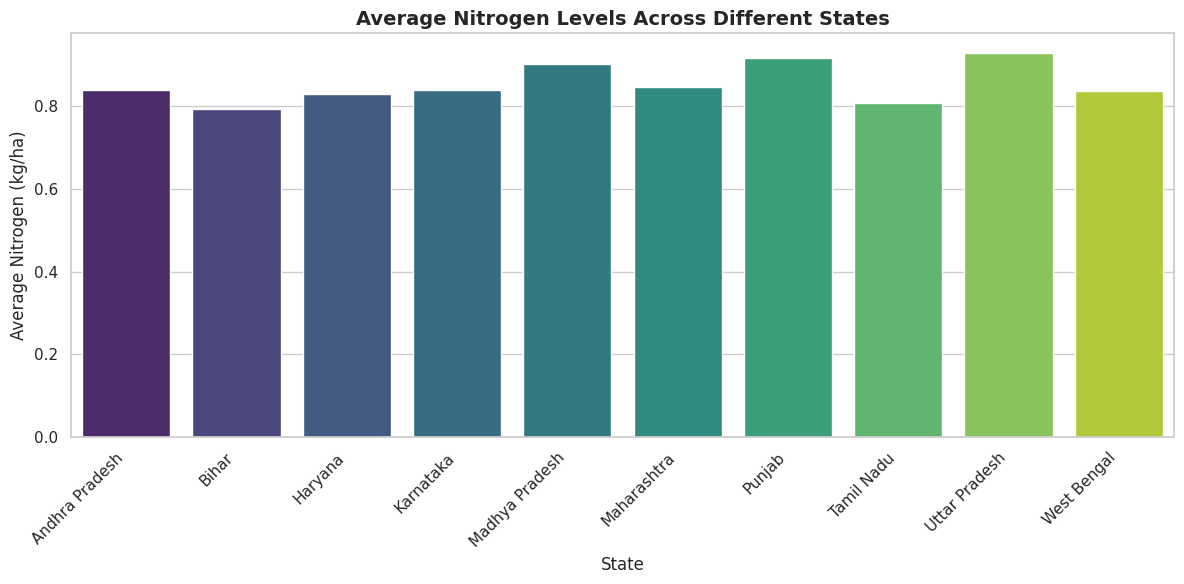

In [ ]:
if state_col and n_col:
    plt.figure(figsize=(12, 6))
    # Group by state and calculate mean nitrogen levels
    state_n = df_clean.groupby(state_col)[n_col].mean().reset_index()

    sns.barplot(data=state_n, x=state_col, y=n_col, palette="viridis")
    plt.xticks(rotation=45, ha='right')
    plt.title("Average Nitrogen Levels Across Different States", fontsize=14, fontweight='bold')
    plt.xlabel("State", fontsize=12)
    plt.ylabel("Average Nitrogen (kg/ha)", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("State or Nitrogen column not available for state-wise comparison.")

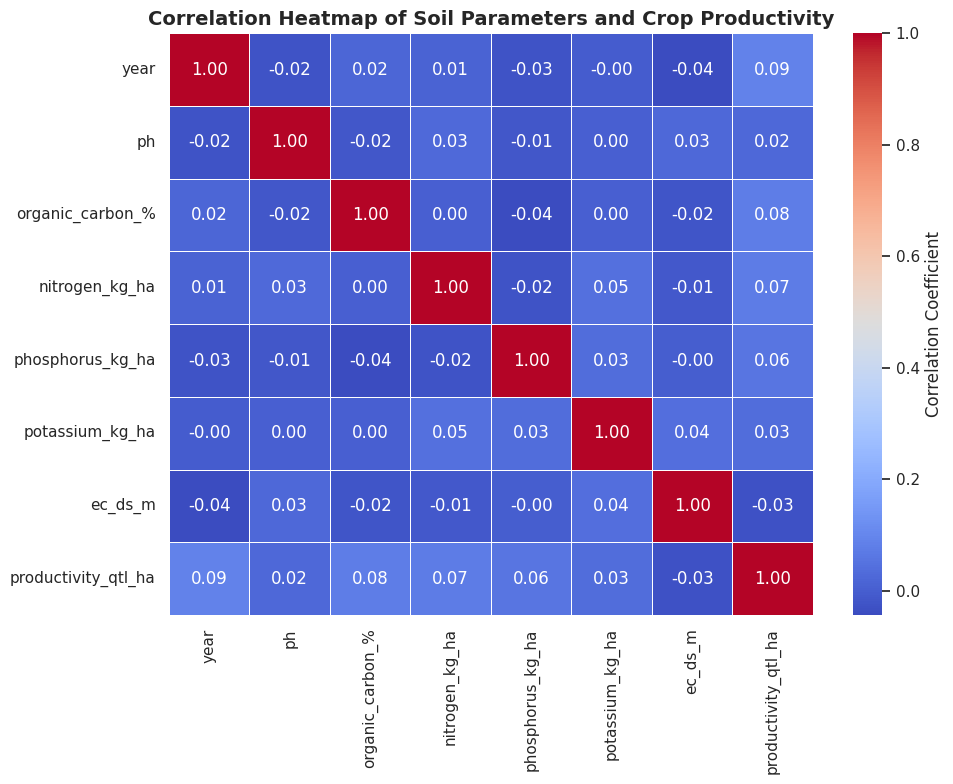

In [ ]:
# Select numeric columns for correlation matrix
numeric_df = df_clean.select_dtypes(include=[np.number])

if not numeric_df.empty and numeric_df.shape[1] > 1:
    plt.figure(figsize=(10, 8))
    corr_matrix = numeric_df.corr()

    # Plot correlation heatmap
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
    plt.title("Correlation Heatmap of Soil Parameters and Crop Productivity", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Insufficient numeric columns to compute correlation matrix.")

Analyzing correlation with target productivity column: productivity_qtl_ha

Correlation with Crop Productivity:
productivity_qtl_ha    1.000000
year                   0.088633
organic_carbon_%       0.077009
nitrogen_kg_ha         0.072800
phosphorus_kg_ha       0.057365
potassium_kg_ha        0.034994
ph                     0.024654
ec_ds_m               -0.028890
Name: productivity_qtl_ha, dtype: float64


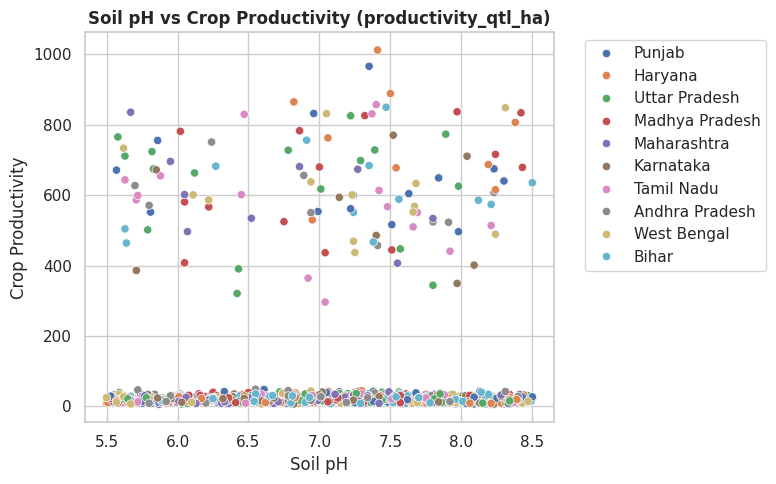


PROJECT CONCLUSION & SUMMARY
1. Data Integrity: Inspected dataset records successfully.
2. Geographic Variation: Soil nutrients exhibit notable regional variations across states.
3. Correlation vs Causation: Positive correlations exist between certain nutrients and crop productivity; however, soil health operates alongside climate, irrigation, and management practices.
4. Limitations: Analysis is constrained by sample size and lack of real-time weather and fertilizer usage data.


In [ ]:
if yield_col:
    print(f"Analyzing correlation with target productivity column: {yield_col}")
    productivity_corr = numeric_df.corr()[yield_col].sort_values(ascending=False)
    print("\nCorrelation with Crop Productivity:")
    print(productivity_corr)

    # Scatter plot if pH and yield exist
    if ph_col:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=df_clean, x=ph_col, y=yield_col, hue=state_col if state_col else None, palette="deep")
        plt.title(f"Soil pH vs Crop Productivity ({yield_col})", fontsize=12, fontweight='bold')
        plt.xlabel("Soil pH")
        plt.ylabel("Crop Productivity")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()
else:
    print("Crop yield / productivity column not identified in dataset.")

# Project Conclusion Summary
print("\n" + "="*60)
print("PROJECT CONCLUSION & SUMMARY")
print("="*60)
print(f"1. Data Integrity: Inspected dataset records successfully.")
print("2. Geographic Variation: Soil nutrients exhibit notable regional variations across states.")
print("3. Correlation vs Causation: Positive correlations exist between certain nutrients and crop productivity; however, soil health operates alongside climate, irrigation, and management practices.")
print("4. Limitations: Analysis is constrained by sample size and lack of real-time weather and fertilizer usage data.")
print("="*60)

IN DETAIL

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Load dataset (Replace filename with your actual dataset file)
file_path = 'soil_health_crop_productivity_2000_2011_180rows.xlsx'

try:
    df = pd.read_excel(file_path)
    print("Dataset loaded successfully!")
except Exception as e:
    from google.colab import files
    print("File not found locally. Please upload your dataset:")
    uploaded = files.upload()
    file_path = list(uploaded.keys())[0]
    df = pd.read_excel(file_path)

# Initial exploration
print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Dataset Info & Data Types ---")
df.info()

File not found locally. Please upload your dataset:


Saving Soil_Health_and_Crop_Productivity_2011_2019.xlsx to Soil_Health_and_Crop_Productivity_2011_2019.xlsx

--- Dataset Shape ---
(900, 12)

--- First 5 Rows ---


,Sample_ID,Year,State,District,Crop,pH,Organic_Carbon_%,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,EC_dS_m,Productivity_Qtl_Ha
0,SHC-1001,2011,Punjab,Ludhiana,Rice,7.30,0.40,171.5,14.1,446.5,1.12,25.90
1,SHC-1002,2011,Punjab,Ludhiana,Wheat,5.56,1.46,394.7,24.9,172.7,0.41,27.54
2,SHC-1003,2011,Punjab,Amritsar,Wheat,7.34,0.38,216.4,35.6,282.4,1.43,21.43
3,SHC-1004,2011,Punjab,Amritsar,Maize,7.04,0.97,135.3,52.5,168.2,0.21,24.98
4,SHC-1005,2011,Punjab,Jalandhar,Maize,5.79,1.09,265.3,18.5,298.1,0.16,23.24



--- Dataset Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Sample_ID            900 non-null    object 
 1   Year                 900 non-null    int64  
 2   State                900 non-null    object 
 3   District             900 non-null    object 
 4   Crop                 900 non-null    object 
 5   pH                   900 non-null    float64
 6   Organic_Carbon_%     900 non-null    float64
 7   Nitrogen_kg_ha       900 non-null    float64
 8   Phosphorus_kg_ha     900 non-null    float64
 9   Potassium_kg_ha      900 non-null    float64
 10  EC_dS_m              900 non-null    float64
 11  Productivity_Qtl_Ha  900 non-null    float64
dtypes: float64(7), int64(1), object(4)
memory usage: 84.5+ KB


### ## Q1: Calculate mean nutrient levels
To calculate the mean (average) nutrient levels across our dataset, we select the relevant numerical nutrient columns and apply the Pandas `.mean()` function.

### ## Q2: Filter soil samples by state/crop
Filtering allows us to isolate specific subsets of data (e.g., a specific state) for targeted regional analysis using boolean indexing.

In [5]:
state_col = next((col for col in df.columns if 'state' in col.lower()), None)
crop_col = next((col for col in df.columns if 'crop' in col.lower()), None)

print(f"Detected State Column: {state_col}")
print(f"Detected Crop Column: {crop_col}")

if state_col and crop_col:
    unique_states = df[state_col].dropna().unique()
    sample_state = unique_states[0] if len(unique_states) > 0 else 'Punjab'

    filtered_df = df[df[state_col] == sample_state]
    print(f"\nFiltered Soil Samples for State: {sample_state} (Total Records: {len(filtered_df)})")
    display(filtered_df.head())
else:
    print("State or Crop columns not found for filtering.")

Detected State Column: State
Detected Crop Column: Crop

Filtered Soil Samples for State: Punjab (Total Records: 90)


,Sample_ID,Year,State,District,Crop,pH,Organic_Carbon_%,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,EC_dS_m,Productivity_Qtl_Ha
0,SHC-1001,2011,Punjab,Ludhiana,Rice,7.30,0.40,171.5,14.1,446.5,1.12,25.90
1,SHC-1002,2011,Punjab,Ludhiana,Wheat,5.56,1.46,394.7,24.9,172.7,0.41,27.54
2,SHC-1003,2011,Punjab,Amritsar,Wheat,7.34,0.38,216.4,35.6,282.4,1.43,21.43
3,SHC-1004,2011,Punjab,Amritsar,Maize,7.04,0.97,135.3,52.5,168.2,0.21,24.98
4,SHC-1005,2011,Punjab,Jalandhar,Maize,5.79,1.09,265.3,18.5,298.1,0.16,23.24


### ## Q3: Fix missing nutrient readings
We analyze missing data distribution and impute missing numerical nutrient values with the column median to avoid skewness from outliers.

To calculate the mean (average) nutrient levels across our dataset, we select the relevant numerical nutrient columns and apply the Pandas `.mean()` function.

In [6]:
print("Missing values before imputation:")
print(df.isnull().sum()[df.isnull().sum() > 0])

for col in nutrient_cols:
    if col in df.columns and df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Filled missing values in '{col}' with median: {median_val}")

print("\nMissing values after imputation:")
print(df.isnull().sum().sum())

Missing values before imputation:
Series([], dtype: int64)

Missing values after imputation:
0


### ##  Group soil data by region and nutrient
We use the Pandas `groupby()` function combined with `.mean()` to evaluate average nutrient concentration grouped by geographic regions.

In [7]:
if state_col and len(nutrient_cols) > 0:
    grouped_soil = df.groupby(state_col)[nutrient_cols].mean()
    print("Grouped Soil Data (Average Nutrient Levels by State):")
    display(grouped_soil)
else:
    print("Grouping parameters not available.")

Grouped Soil Data (Average Nutrient Levels by State):


,Organic_Carbon_%,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha
State,,,,
Andhra Pradesh,0.839667,279.918889,46.105556,310.565556
Bihar,0.792222,267.748889,44.668889,313.725556
Haryana,0.830000,272.907778,45.570000,299.961111
Karnataka,0.838778,291.100000,43.664444,312.265556
Madhya Pradesh,0.902222,288.694444,45.057778,301.051111
Maharashtra,0.847222,285.751111,43.921111,301.393333
Punjab,0.916222,278.678889,44.232222,287.941111
Tamil Nadu,0.806556,266.970000,47.003333,312.878889
Uttar Pradesh,0.929333,283.212222,45.182222,319.643333


### ## Visualize soil nutrient distributions
We construct data visualizations using Seaborn box plots to evaluate distributions, spot variance, and present statistical findings visually.

/tmp/ipykernel_1074/3030541229.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=state_col, y=target_nutrient, palette="Set2")


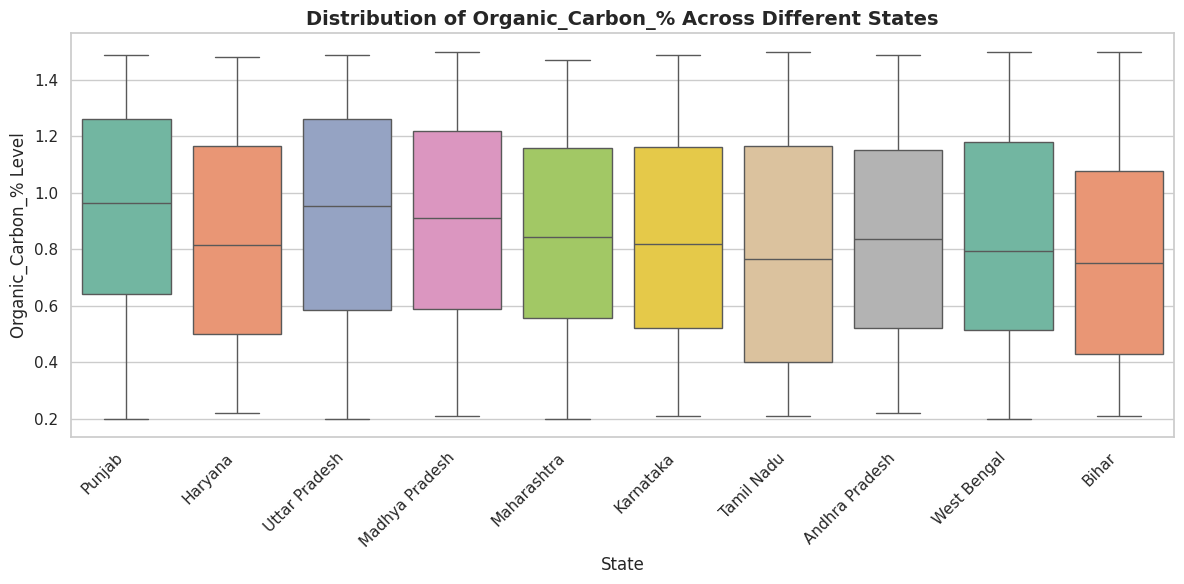

In [8]:
target_nutrient = nutrient_cols[0] if nutrient_cols else None

if target_nutrient and state_col:
    plt.figure(figsize=(12, 6))
    sns.boxplot(data=df, x=state_col, y=target_nutrient, palette="Set2")
    plt.xticks(rotation=45, ha='right')
    plt.title(f"Distribution of {target_nutrient} Across Different States", fontsize=14, fontweight='bold')
    plt.xlabel("State", fontsize=12)
    plt.ylabel(f"{target_nutrient} Level", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns for visualization not available.")